# Rebalancing Bluebikes Across Greater Boston
### IE 5374 · Module 7 Hackathon · Event-aware crew planning with GenAI

**Team:** _add names here_

**What this notebook does, end to end**

1. Downloads real Bluebikes trips (Jan 2024 to Sep 2026) and the station list, and aggregates them to station-hour.
2. Simulates every station-day (start half full, step hour by hour, clip between empty and full) to estimate how many bikes crews must move, by city and day.
3. **GenAI #1, structured output + prompt engineering:** an LLM turns free-text event listings into a validated `EventList` (date, venue, coordinates, crowd size). We map each event to nearby stations and calibrate its impact on rebalancing need from 2024 and 2025 data.
4. Forecasts 2026 daily rebalancing need per city (history + growth + event uplift).
5. Solves a **mixed-integer program** for the month-by-month crew plan (full-time hires, release notices, seasonal contracts) that minimizes crew cost plus lost revenue under every rule in the brief.
6. **Backtests** the plan on real Jan to Sep 2026 trips and runs a **sensitivity analysis** (ridership ±20%, e-bike growth).
7. **GenAI #2, tool-calling agent:** an Operations Assistant that answers questions like "What happens if we add one crew to Cambridge in September?" by calling the model as a tool.

**How to run:** `pip install -r requirements.txt`, set `OPENAI_API_KEY` (or `ANTHROPIC_API_KEY`), then *Run All*. First run downloads about 500 MB and takes roughly 15 to 25 minutes; later runs use the cache in `data/processed/`. Without an API key, the notebook still runs end to end using a documented fallback event table, and the assistant section shows the tools working directly.

**AI use disclosure:** Code in this notebook was drafted with help from Claude (Anthropic) and then reviewed, run, and edited by the team. Sections marked **[AI-assisted]** contain AI-drafted code or text. The event descriptions in Section 4 were drafted with AI and must be verified against the cited sources. All numbers shown come from running the code on real Bluebikes data.

## 0. Setup

In [1]:
   !pip install -q pandas numpy scipy matplotlib requests pydantic langchain-core langchain-google-genai
   import os
   os.environ["GOOGLE_API_KEY"] = ""
   os.environ["LLM_MODEL"] = "gemini-3.5-flash-lite"

In [2]:
# !pip install -q pandas numpy scipy matplotlib requests pydantic langchain-core langchain-google-genai

import os, io, json, math, zipfile, warnings, datetime as dt
os.environ["GOOGLE_API_KEY"] = ""   # <- uncomment and paste your key
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import coo_matrix

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

try:
    from IPython.display import display, Markdown
except ImportError:  # plain python fallback
    display = print
    Markdown = str

DATA = Path("data"); RAW = DATA / "raw"; PROC = DATA / "processed"; OUT = Path("outputs")
for p in (RAW, PROC, OUT):
    p.mkdir(parents=True, exist_ok=True)

## 1. Planning assumptions (from the brief, marked ASSUMED there)

| Item | Value | Derived |
|---|---|---|
| Crew capacity | 120 bikes/shift, 6 shifts/week | 120 × 6 / 7 ≈ **102.9 bikes per crew per calendar day** |
| Full-time crew | $54,000/yr driver + $1,500/mo van | **$6,000/month** while working |
| Full-time hire | 1 month to recruit and train | We assume the trainee is paid ($4,500) but has no van and moves no bikes that month |
| Full-time release | 1 month notice, 25% of salary | **$13,500** one-time; driver still works the notice month |
| Seasonal crew | $7,800/month all-in | Starts the month after signing, 3-month minimum, max 8 system-wide |
| Lost rider event | 40% walk ($0), 45% lost ride ($3.25), 15% lost ride + member ($28.25) | **$5.70 expected loss** |
| January 2026 crews | Boston 6, Cambridge 4, Somerville 1, Brookline 1, Other 2 | Treated as full-time |

In [3]:
CITIES = ["Boston", "Cambridge", "Somerville", "Brookline", "Other"]
START_CREWS = {"Boston": 6, "Cambridge": 4, "Somerville": 1, "Brookline": 1, "Other": 2}

BIKES_PER_SHIFT, SHIFTS_PER_WEEK = 120, 6
CREW_DAILY_CAP = BIKES_PER_SHIFT * SHIFTS_PER_WEEK / 7          # bikes per crew per calendar day

FT_SALARY = 54_000
FT_MONTHLY = FT_SALARY / 12 + 1_500                             # 6,000
FT_TRAINING_MONTH = FT_SALARY / 12                              # 4,500 (assumption)
FT_RELEASE = 0.25 * FT_SALARY                                   # 13,500
SEASONAL_MONTHLY, SEASONAL_MIN_MONTHS, SEASONAL_CAP = 7_800, 3, 8

RIDE_REV = 3.25
LOST_PER_EVENT = 0.40 * 0 + 0.45 * RIDE_REV + 0.15 * (RIDE_REV + 25)   # 5.70

HIST_START, HIST_END = "2024-01-01", "2025-12-31"
TEST_START, TEST_END = "2026-01-01", "2026-09-30"
DAY0 = pd.Timestamp("2024-01-01")

print(f"Crew capacity: {CREW_DAILY_CAP:.1f} bikes/day, {CREW_DAILY_CAP*30.4:,.0f} bikes/month")
print(f"Full-time: ${FT_MONTHLY:,.0f}/mo | Seasonal: ${SEASONAL_MONTHLY:,.0f}/mo | Release: ${FT_RELEASE:,.0f}")
print(f"Expected loss per unmet rider event: ${LOST_PER_EVENT:.2f}")
print(f"A crew pays for itself if it prevents > {FT_MONTHLY/LOST_PER_EVENT:,.0f} lost rider events per month")

Crew capacity: 102.9 bikes/day, 3,127 bikes/month
Full-time: $6,000/mo | Seasonal: $7,800/mo | Release: $13,500
Expected loss per unmet rider event: $5.70
A crew pays for itself if it prevents > 1,053 lost rider events per month


## 2. Data: download and aggregate to station-hour

File names vary by month (`.zip`, `.csv.zip`, plain `.csv`), so the downloader tries each pattern. Each month is aggregated to **station × date × hour** pickups and returns, split by classic vs e-bike, and cached. We never keep raw trips in memory.

In [4]:
BUCKET = "https://s3.amazonaws.com/hubway-data/"
MONTHS = [p.strftime("%Y%m") for p in pd.period_range("2024-01", "2026-09", freq="M")]
SUFFIXES = ("-bluebikes-tripdata.zip", "-bluebikes-tripdata.csv.zip", "-bluebikes-tripdata.csv")

def download_month(ym):
    for sfx in SUFFIXES:                                    
        f = RAW / f"{ym}{sfx}"
        if f.exists() and f.stat().st_size > 0:
            return f
    for sfx in SUFFIXES:
        f = RAW / f"{ym}{sfx}"
        try:
            r = requests.get(BUCKET + ym + sfx, timeout=180, stream=True)
            if r.status_code != 200:
                continue
            tmp = f.with_suffix(f.suffix + ".part")
            with open(tmp, "wb") as fh:
                for chunk in r.iter_content(1 << 20):
                    fh.write(chunk)
            tmp.rename(f)
            return f
        except requests.RequestException as e:
            print(f"  {ym}{sfx}: {e}")
    print(f"  WARNING: could not find trips for {ym}")
    return None

USECOLS = {"rideable_type", "started_at", "ended_at", "start_station_id", "end_station_id",
           "start_lat", "start_lng", "member_casual"}
STR_COLS = {"start_station_id": str, "end_station_id": str, "rideable_type": str, "member_casual": str}

def read_trip_file(path):
    kw = dict(usecols=lambda c: c in USECOLS, dtype=STR_COLS, low_memory=False)
    if path.suffix == ".zip":
        with zipfile.ZipFile(path) as z:
            names = [n for n in z.namelist() if n.lower().endswith(".csv") and "__macosx" not in n.lower()]
            name = max(names, key=lambda n: z.getinfo(n).file_size)
            with z.open(name) as fh:
                return pd.read_csv(fh, **kw)
    return pd.read_csv(path, **kw)

def _counts(frame, prefix):
    g = frame.groupby(["sid", "date", "hour", "e"]).size().unstack("e", fill_value=0)
    g = g.reindex(columns=[0, 1], fill_value=0)
    g.columns = [prefix + "c", prefix + "e"]                 # classic, electric
    return g

def aggregate_month(ym):
    cache = PROC / f"agg_{ym}.pkl"
    if cache.exists():
        return pd.read_pickle(cache)
    path = download_month(ym)
    if path is None:
        return None
    df = read_trip_file(path)
    st = pd.to_datetime(df["started_at"], errors="coerce", format="ISO8601")
    en = pd.to_datetime(df["ended_at"], errors="coerce", format="ISO8601")
    e = df["rideable_type"].astype(str).str.contains("electric", case=False).astype(np.int8)
    sides = []
    for ts, sid, pre in ((st, "start_station_id", "p"), (en, "end_station_id", "r")):
        f = pd.DataFrame({"sid": df[sid].astype(str).str.strip(), "date": ts.dt.floor("D"),
                          "hour": ts.dt.hour, "e": e})
        f = f[f["sid"].notna() & ~f["sid"].isin(["", "nan", "None", "<NA>"])].dropna(subset=["date", "hour"])
        f["hour"] = f["hour"].astype(np.int8)
        sides.append(_counts(f, pre))
    hourly = sides[0].join(sides[1], how="outer").fillna(0).astype(np.int32).reset_index()
    coords = (df.assign(sid=df["start_station_id"].astype(str).str.strip())
                .groupby("sid")[["start_lat", "start_lng"]].median())
    summary = {"month": ym, "trips": len(df), "ebike_trips": int(e.sum()),
               "member_trips": int((df["member_casual"].astype(str) == "member").sum())}
    out = {"hourly": hourly, "coords": coords, "summary": summary}
    pd.to_pickle(out, cache)
    return out

aggs = {}
for ym in MONTHS:
    a = aggregate_month(ym)
    if a is not None:
        aggs[ym] = a
        print(f"{ym}: {a['summary']['trips']:>8,} trips")

hourly = (pd.concat([a["hourly"] for a in aggs.values()], ignore_index=True)
            .groupby(["sid", "date", "hour"], as_index=False).sum())
hourly = hourly[(hourly["date"] >= DAY0) & (hourly["date"] <= pd.Timestamp(TEST_END))].reset_index(drop=True)
coords = pd.concat([a["coords"] for a in aggs.values()]).groupby(level=0).median()
monthly_summary = pd.DataFrame([a["summary"] for a in aggs.values()])
monthly_summary["ebike_share"] = monthly_summary["ebike_trips"] / monthly_summary["trips"]
print(f"\nStation-hour rows: {len(hourly):,} | stations seen in trips: {hourly['sid'].nunique()}")

202401:  166,699 trips
202402:  231,947 trips
202403:  261,687 trips
202404:  356,327 trips
202405:  440,534 trips
202406:  478,860 trips
202407:  542,622 trips
202408:  538,262 trips
202409:  582,679 trips
202410:  564,156 trips
202411:  397,406 trips
202412:  190,611 trips
202501:  162,316 trips
202502:  166,022 trips
202503:  272,088 trips
202504:  373,940 trips
202505:  429,840 trips
202506:  488,202 trips
202507:  539,711 trips
202508:  549,014 trips
202509:  586,979 trips
202510:  513,531 trips
202511:  344,841 trips
202512:  187,816 trips
202601:  152,074 trips
202602:  136,508 trips
202603:  253,780 trips
202604:  368,431 trips
202605:  432,675 trips
202606:  515,776 trips
202607:  530,297 trips
202608:  582,663 trips
202609:  555,205 trips

Station-hour rows: 5,893,639 | stations seen in trips: 642


### 2b. Station list: docks and city

We join on station ID first. If an ID is missing from the current station list (renamed or retired stations), we fall back to the historic-ID column, then to the nearest listed station within 250 m using trip coordinates. Anything still unmatched goes to "Other" with the median dock count.

In [5]:
STATION_URLS = ["https://s3.amazonaws.com/hubway-data/current_bluebikes_stations.csv"]

def load_station_list():
    f = RAW / "stations.csv"
    if not f.exists():
        for url in STATION_URLS:
            try:
                r = requests.get(url, timeout=60)
                if r.status_code == 200:
                    f.write_bytes(r.content); break
            except requests.RequestException:
                pass
    if not f.exists():
        raise FileNotFoundError("Download the station CSV from https://bluebikes.com/system-data and save it as data/raw/stations.csv")
    lines = f.read_text(errors="ignore").splitlines()
    hdr = next((i for i, l in enumerate(lines[:15])
                if "municipality" in l.lower() or ("number" in l.lower() and "name" in l.lower())), 0)
    s = pd.read_csv(f, skiprows=hdr, dtype=str)
    cols = {c.lower().strip(): c for c in s.columns}
    def find(*keys, exclude=()):
        for lc, c in cols.items():
            if any(k in lc for k in keys) and not any(x in lc for x in exclude):
                return c
    id_col = find("number") or find("station id")
    alt_col = find("historic", "station id", exclude=(id_col.lower(),) if id_col else ())
    out = pd.DataFrame({
        "sid": s[id_col].astype(str).str.strip(),
        "alt_id": s[alt_col].astype(str).str.strip() if alt_col and alt_col != id_col else None,
        "name": s[find("name")],
        "lat": pd.to_numeric(s[find("lat")], errors="coerce"),
        "lon": pd.to_numeric(s[find("lon", "lng")], errors="coerce"),
        "municipality": s[find("municipality", "district", "city")].astype(str).str.strip(),
        "docks": pd.to_numeric(s[find("dock")], errors="coerce"),
    })
    return out

def norm_city(m):
    m = str(m).strip().title()
    return m if m in CITIES[:4] else "Other"

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

stations = load_station_list()
stations["city"] = stations["municipality"].map(norm_city)
median_docks = float(stations["docks"].median())
print(f"Station list: {len(stations)} stations, median docks {median_docks:.0f}")
print(stations["city"].value_counts().to_string())

# Build attributes for every station ID seen in the trips
trip_sids = pd.Index(sorted(hourly["sid"].unique()))
by_id = stations.drop_duplicates("sid").set_index("sid")
by_alt = stations.dropna(subset=["alt_id"]).drop_duplicates("alt_id").set_index("alt_id") if stations["alt_id"].notna().any() else None
attrs, how = [], {"id": 0, "alt_id": 0, "nearest": 0, "unmatched": 0}
st_lat, st_lon = stations["lat"].to_numpy(), stations["lon"].to_numpy()
for sid in trip_sids:
    row = None
    if sid in by_id.index:
        row, k = by_id.loc[sid], "id"
    elif by_alt is not None and sid in by_alt.index:
        row, k = by_alt.loc[sid], "alt_id"
    elif sid in coords.index and coords.loc[sid].notna().all():
        d = haversine_km(coords.loc[sid, "start_lat"], coords.loc[sid, "start_lng"], st_lat, st_lon)
        j = np.nanargmin(d)
        if d[j] < 0.25:
            row, k = stations.iloc[j], "nearest"
    if row is None:
        k = "unmatched"
        attrs.append({"sid": sid, "name": sid, "city": "Other", "docks": median_docks})
    else:
        attrs.append({"sid": sid, "name": row["name"], "city": row["city"],
                      "docks": row["docks"] if pd.notna(row["docks"]) and row["docks"] > 0 else median_docks})
    how[k] += 1
station_attrs = pd.DataFrame(attrs).set_index("sid")
print("Station ID matching:", how)

SID_CODE = {s: i for i, s in enumerate(station_attrs.index)}
CAP = station_attrs["docks"].to_numpy(float)
CITY_OF = station_attrs["city"].to_numpy()
hourly["sid_code"] = hourly["sid"].map(SID_CODE).astype(np.int32)
hourly["day"] = (hourly["date"] - DAY0).dt.days.astype(np.int32)

Station list: 613 stations, median docks 17
city
Boston        352
Other         105
Cambridge      96
Somerville     40
Brookline      20
Station ID matching: {'id': 0, 'alt_id': 0, 'nearest': 631, 'unmatched': 11}


## 3. Demand & imbalance model 

**Method (as suggested in the brief):** every station starts each day half full. For each hour we add returns and subtract pickups. If stock goes below 0, those riders found no bike (**shortage**). If it goes above the dock count, those riders found no free dock (**overflow**). We clip back into range, which is equivalent to assuming a crew fixed it, and continue.

**Bikes to move per station-day = shortage + overflow.** Summing over a city gives that city's daily rebalancing need. If crews can't cover it, each uncovered unit is one rider who couldn't ride or return, costing $5.70 on average.

Limitations we accept: pickups and returns inside the same hour net out (this understates need), and the overnight reset to half full is not counted as crew work.

In [6]:
def simulate(h, demand_scale=1.0, e_mult=1.0, c_mult=1.0):
    """Station-day shortage/overflow from station-hour flows. Multipliers support scenarios."""
    pick = (h["pc"].to_numpy(float) * c_mult + h["pe"].to_numpy(float) * e_mult) * demand_scale
    ret = (h["rc"].to_numpy(float) * c_mult + h["re"].to_numpy(float) * e_mult) * demand_scale
    key = h["sid_code"].to_numpy(np.int64) * 4000 + h["day"].to_numpy(np.int64)
    uk, inv = np.unique(key, return_inverse=True)
    M = np.zeros((len(uk), 24))
    M[inv, h["hour"].to_numpy()] = ret - pick                 # rows are unique per station-day-hour
    sc = (uk // 4000).astype(int)
    cap = CAP[sc]
    stock, short, over = cap / 2, np.zeros(len(uk)), np.zeros(len(uk))
    for t in range(24):
        stock = stock + M[:, t]
        s, o = np.clip(-stock, 0, None), np.clip(stock - cap, 0, None)
        short += s; over += o
        stock = np.clip(stock, 0, cap)
    res = pd.DataFrame({"sid_code": sc, "day": (uk % 4000).astype(int), "shortage": short,
                        "overflow": over, "net": M.sum(1)})
    res["need"] = res["shortage"] + res["overflow"]
    res["city"] = CITY_OF[sc]
    res["date"] = DAY0 + pd.to_timedelta(res["day"], unit="D")
    return res

def city_daily_from(res, start=HIST_START, end=TEST_END):
    g = res.groupby(["city", "date"])[["shortage", "overflow", "need"]].sum()
    full = pd.MultiIndex.from_product([CITIES, pd.date_range(start, end)], names=["city", "date"])
    return g.reindex(full, fill_value=0.0)

station_day = simulate(hourly)
city_daily = city_daily_from(station_day)
cd = city_daily.reset_index()
cd["month"] = cd["date"].dt.to_period("M")

city_month = cd.pivot_table(index="month", columns="city", values="need", aggfunc="sum")[CITIES]
print("Bikes to move per month (thousands):")
display((city_month / 1000).round(1))

Bikes to move per month (thousands):


city,Boston,Cambridge,Somerville,Brookline,Other
month,,,,,
2024-01,3.3,4.2,0.2,0.2,0.0
2024-02,5.3,8.3,0.4,0.3,0.0
2024-03,6.3,7.8,0.5,0.3,0.0
2024-04,10.6,12.0,1.1,0.5,0.1
2024-05,15.5,15.5,1.8,0.7,0.2
2024-06,19.1,15.8,1.8,1.0,0.2
2024-07,21.2,20.7,2.0,1.1,0.2
2024-08,20.5,19.9,1.8,1.1,0.2
2024-09,22.8,23.9,2.3,1.5,0.3


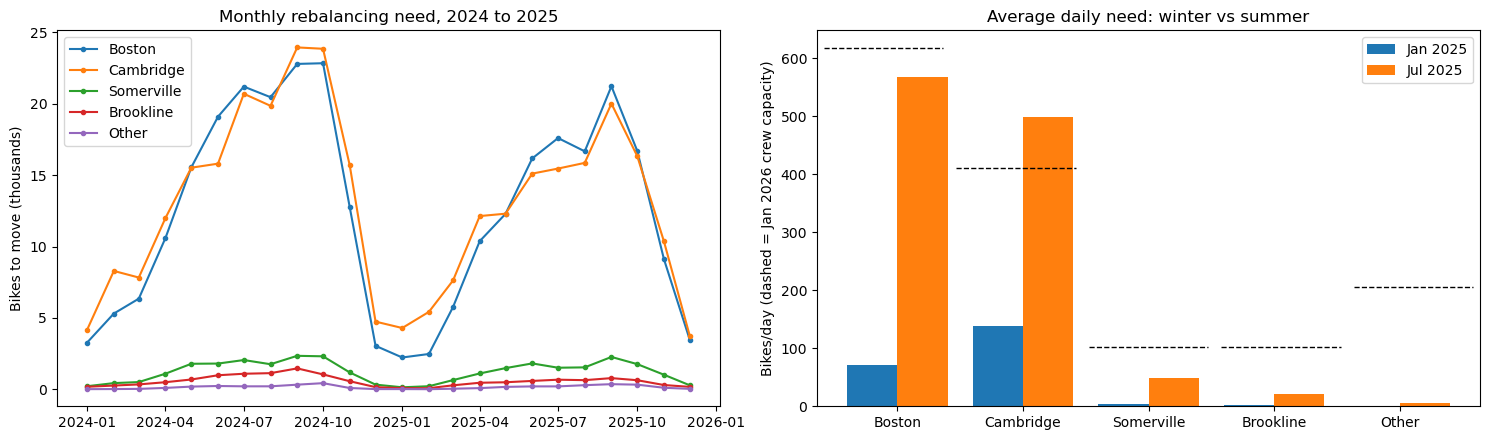

July / January need ratio: {'Boston': 7.9, 'Cambridge': 3.6, 'Somerville': 11.1, 'Brookline': 8.9, 'Other': 20.0}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
hist = city_month.loc[:"2025-12"]
for c in CITIES:
    axes[0].plot(hist.index.to_timestamp(), hist[c] / 1000, marker="o", ms=3, label=c)
axes[0].set_title("Monthly rebalancing need, 2024 to 2025"); axes[0].set_ylabel("Bikes to move (thousands)")
axes[0].legend()

# Summer vs winter: average daily need, July vs January (2025)
jul = cd[cd["month"] == pd.Period("2025-07")].groupby("city")["need"].mean()
jan = cd[cd["month"] == pd.Period("2025-01")].groupby("city")["need"].mean()
x = np.arange(len(CITIES))
axes[1].bar(x - 0.2, jan.reindex(CITIES), 0.4, label="Jan 2025")
axes[1].bar(x + 0.2, jul.reindex(CITIES), 0.4, label="Jul 2025")
axes[1].set_xticks(x, CITIES); axes[1].set_title("Average daily need: winter vs summer")
for i, c in enumerate(CITIES):
    axes[1].axhline(START_CREWS[c] * CREW_DAILY_CAP, xmin=(i + 0.05) / len(CITIES), xmax=(i + 0.95) / len(CITIES),
                    color="k", ls="--", lw=1)
axes[1].legend(); axes[1].set_ylabel("Bikes/day (dashed = Jan 2026 crew capacity)")
plt.tight_layout(); plt.show()

ratio = (jul / jan.replace(0, np.nan)).reindex(CITIES)
print("July / January need ratio:", ratio.round(1).to_dict())

## 4. Event awareness with GenAI 
**Technique: structured output + prompt engineering.** We give the LLM free-text event listings and a Pydantic schema. It returns a validated `EventList` with dates, venue coordinates, and total crowd size. We then:

* map each event to the stations within 1 km of the venue, which also splits impact across cities (Head of the Charles touches both Boston and Cambridge);
* **calibrate** how much an event changes rebalancing need, by comparing 2024 to 2025 event days with normal days of the same city, month, and weekday;
* add the calibrated uplift to 2026 event days in the forecast.

Red Sox home games come from the public MLB Stats API (already structured, so no LLM needed). Free-text events go through the LLM.

> **Verify before submitting:** the event text below was drafted with AI from public sources. Check each date and figure against the official sites (baa.org, hocr.org, bso.org, bostoncalling.com, harvard.edu, mit.edu, boston.gov) and cite them in the README.

In [21]:
EVENT_TEXT = """
Boston Marathon 2024: The 128th Boston Marathon ran on Monday, April 15, 2024 (Patriots' Day), finishing on Boylston Street in Back Bay near Copley Square. About 30,000 runners took part and an estimated 500,000 spectators lined the course.

Boston Marathon 2025: The 129th Boston Marathon was held Monday, April 21, 2025, with the finish line on Boylston Street at Copley Square. Roughly 30,000 runners and crowds of about 500,000.

Boston Marathon 2026: The 130th Boston Marathon is scheduled for Monday, April 20, 2026, finishing on Boylston Street in Back Bay.

Head of the Charles Regatta: the world's largest two-day rowing event, held on the Charles River between Cambridge and Boston, with spectators concentrated near the Weeks Footbridge and Eliot Bridge. Dates: October 19-20, 2024; October 18-19, 2025; October 17-18, 2026. Organizers report around 200,000 spectators over the weekend.

Boston Pops Fourth of July Fireworks Spectacular at the DCR Hatch Shell on the Charles River Esplanade, held every July 4 (2024, 2025 and 2026). Crowds gather on the Esplanade and both banks of the river; an often-cited figure is 500,000 people.

Boston Calling Music Festival at the Harvard Athletic Complex in Allston, Memorial Day weekend: May 24-26, 2024; May 23-25, 2025; and May 22-24, 2026. About 40,000 attendees per day.

September 1 move-in ("Allston Christmas"): Boston's citywide lease turnover day, concentrated in Allston, Brighton, Fenway and Mission Hill. It happens every September 1 (2024, 2025, 2026), with an estimated 50,000 students and renters moving.

College move-in in Cambridge: Harvard and MIT undergraduate move-in happens in late August, approximately August 25-27 in 2024, 2025 and 2026 (approximate). About 15,000 students plus families.

First Night Boston: New Year's Eve celebration at Copley Square and Boston Common every December 31 (2024, 2025, 2026), drawing roughly 100,000 people.
"""

EXTRACTION_SYSTEM_PROMPT = """You extract public events that affect bike-share demand in Greater Boston.
Return one entry per occurrence per year (a recurring event held in 2024, 2025 and 2026 is three entries).
Rules:
- Dates in ISO format. Multi-day events: one entry with start_date and end_date.
- latitude/longitude: the main venue or finish area (e.g. Fenway Park 42.3467,-71.0972; Copley Square 42.3499,-71.0778).
- city must be one of: Boston, Cambridge, Somerville, Brookline, Other.
- expected_attendance: TOTAL people over the whole event (runners + spectators, or attendees per day x days).
  If a year's figure is missing, reuse the figure stated for the same recurring event. Never return 0.
- category: sports, festival, civic, academic, or other.
- Only include events explicitly described in the text. Do not invent events."""
def get_llm():
    """Gemini, OpenAI, or Anthropic, whichever key is set. Returns None if no key or packages."""
    try:
        if os.getenv("GOOGLE_API_KEY") or os.getenv("GEMINI_API_KEY"):
            from langchain_google_genai import ChatGoogleGenerativeAI
            key = os.getenv("GOOGLE_API_KEY") or os.getenv("GEMINI_API_KEY")
            return ChatGoogleGenerativeAI(model=os.getenv("LLM_MODEL", "gemini-2.5-flash"), temperature=0, google_api_key=key, max_retries=8, timeout=120)
        if os.getenv("OPENAI_API_KEY"):
            from langchain_openai import ChatOpenAI
            return ChatOpenAI(model=os.getenv("LLM_MODEL", "gpt-4o-mini"), temperature=0)
        if os.getenv("ANTHROPIC_API_KEY"):
            from langchain_anthropic import ChatAnthropic
            return ChatAnthropic(model=os.getenv("LLM_MODEL", "claude-haiku-5-5"), temperature=0)
    except ImportError as e:
        print("LLM package missing:", e)
    return None

llm = get_llm()
print("LLM:", type(llm).__name__ if llm else "none (using fallback paths)")

try:
    from typing import Literal
    from pydantic import BaseModel, Field

    class Event(BaseModel):
        name: str = Field(description="Event name including year, e.g. 'Boston Marathon 2025'")
        start_date: str = Field(description="YYYY-MM-DD")
        end_date: str = Field(description="YYYY-MM-DD; same as start_date for one-day events")
        venue: str
        city: Literal["Boston", "Cambridge", "Somerville", "Brookline", "Other"]
        latitude: float
        longitude: float
        expected_attendance: int = Field(description="Total people over the whole event, always > 0")
        category: Literal["sports", "festival", "civic", "academic", "other"]

    class EventList(BaseModel):
        events: list[Event]
    HAVE_PYDANTIC = True
except ImportError:
    HAVE_PYDANTIC = False

def extract_events_llm(text):
    extractor = llm.with_structured_output(EventList)
    chunks = [p.strip() for p in text.strip().split("\n\n") if p.strip()]
    events = []
    for i in range(0, len(chunks), 3):                       # small batches = fewer extraction misses
        batch = "\n\n".join(chunks[i:i + 3])
        result = extractor.invoke([("system", EXTRACTION_SYSTEM_PROMPT), ("human", batch)])
        events += [e.model_dump() for e in result.events]
    return pd.DataFrame(events)

# Fallback used only when no API key is available: the same events, entered by hand from EVENT_TEXT.
def _ev(name, s, e, venue, city, lat, lon, att, cat):
    return dict(name=name, start_date=s, end_date=e, venue=venue, city=city, latitude=lat,
                longitude=lon, expected_attendance=att, category=cat)
FALLBACK_EVENTS = []
for y, d in ((2024, "04-15"), (2025, "04-21"), (2026, "04-20")):
    FALLBACK_EVENTS.append(_ev(f"Boston Marathon {y}", f"{y}-{d}", f"{y}-{d}", "Boylston St finish", "Boston", 42.3499, -71.0790, 530000, "sports"))
for y, s, e in ((2024, "10-19", "10-20"), (2025, "10-18", "10-19"), (2026, "10-17", "10-18")):
    FALLBACK_EVENTS.append(_ev(f"Head of the Charles {y}", f"{y}-{s}", f"{y}-{e}", "Charles River at Weeks Footbridge", "Cambridge", 42.3693, -71.1200, 200000, "sports"))
for y in (2024, 2025, 2026):
    FALLBACK_EVENTS.append(_ev(f"July 4 Pops Fireworks {y}", f"{y}-07-04", f"{y}-07-04", "Hatch Shell, Esplanade", "Boston", 42.3580, -71.0740, 500000, "civic"))
    FALLBACK_EVENTS.append(_ev(f"Allston Christmas move-in {y}", f"{y}-09-01", f"{y}-09-01", "Allston-Brighton", "Boston", 42.3539, -71.1337, 50000, "civic"))
    FALLBACK_EVENTS.append(_ev(f"Harvard/MIT move-in {y}", f"{y}-08-25", f"{y}-08-27", "Harvard Yard / MIT campus", "Cambridge", 42.3656, -71.1040, 15000, "academic"))
    FALLBACK_EVENTS.append(_ev(f"First Night Boston {y}", f"{y}-12-31", f"{y}-12-31", "Copley Square / Boston Common", "Boston", 42.3530, -71.0700, 100000, "festival"))
for y, s, e in ((2024, "05-24", "05-26"), (2025, "05-23", "05-25"), (2026, "05-22", "05-24")):
    FALLBACK_EVENTS.append(_ev(f"Boston Calling {y}", f"{y}-{s}", f"{y}-{e}", "Harvard Athletic Complex, Allston", "Boston", 42.3655, -71.1255, 120000, "festival"))

if llm is not None and HAVE_PYDANTIC:
    try:
        text_events = extract_events_llm(EVENT_TEXT)
        text_events["source"] = "LLM extraction"
    except Exception as ex:
        print("LLM extraction failed, using fallback:", ex)
        text_events = pd.DataFrame(FALLBACK_EVENTS); text_events["source"] = "fallback (hand-entered)"
else:
    text_events = pd.DataFrame(FALLBACK_EVENTS); text_events["source"] = "fallback (hand-entered)"

# Validation guardrails on LLM output
text_events["start_date"] = pd.to_datetime(text_events["start_date"])
text_events["end_date"] = pd.to_datetime(text_events["end_date"])
text_events["end_date"] = text_events[["start_date", "end_date"]].max(axis=1)
ok = (text_events["latitude"].between(42.2, 42.5) & text_events["longitude"].between(-71.3, -70.9)
      & text_events["start_date"].between("2024-01-01", "2026-12-31") & (text_events["expected_attendance"] > 0))
if (~ok).any():
    print("Dropping invalid extracted rows:\n", text_events.loc[~ok, ["name", "start_date", "latitude", "longitude"]])
text_events = text_events[ok].drop_duplicates(["name", "start_date"]).reset_index(drop=True)
display(text_events[["name", "start_date", "end_date", "venue", "city", "expected_attendance", "category", "source"]])

LLM: ChatGoogleGenerativeAI


,name,start_date,end_date,venue,city,expected_attendance,category,source
0,Boston Marathon 2024,2024-04-15,2024-04-15,Copley Square,Boston,530000,sports,LLM extraction
1,Boston Marathon 2025,2025-04-21,2025-04-21,Copley Square,Boston,530000,sports,LLM extraction
2,Boston Marathon 2026,2026-04-20,2026-04-20,Boylston Street,Boston,530000,sports,LLM extraction
3,Head of the Charles Regatta 2024,2024-10-19,2024-10-20,Charles River,Boston,200000,sports,LLM extraction
4,Head of the Charles Regatta 2025,2025-10-18,2025-10-19,Charles River,Boston,200000,sports,LLM extraction
5,Head of the Charles Regatta 2026,2026-10-17,2026-10-18,Charles River,Boston,200000,sports,LLM extraction
6,Boston Pops Fourth of July Fireworks Spectacul...,2024-07-04,2024-07-04,DCR Hatch Shell,Boston,500000,festival,LLM extraction
7,Boston Pops Fourth of July Fireworks Spectacul...,2025-07-04,2025-07-04,DCR Hatch Shell,Boston,500000,festival,LLM extraction
8,Boston Pops Fourth of July Fireworks Spectacul...,2026-07-04,2026-07-04,DCR Hatch Shell,Boston,500000,festival,LLM extraction
9,Boston Calling Music Festival 2024,2024-05-24,2024-05-26,Harvard Athletic Complex,Boston,120000,festival,LLM extraction


In [22]:
FENWAY = (42.3467, -71.0972)
REDSOX_ATTENDANCE = 32_000      # assumption: typical Fenway crowd (capacity ~37,000)

def fetch_redsox_home(season):
    url = f"https://statsapi.mlb.com/api/v1/schedule?sportId=1&teamId=111&season={season}&gameType=R"
    cache = RAW / f"redsox_{season}.json"
    if cache.exists():
        js = json.loads(cache.read_text())
    else:
        js = requests.get(url, timeout=30).json()
        cache.write_text(json.dumps(js))
    rows = []
    for d in js.get("dates", []):
        for g in d.get("games", []):
            if g["teams"]["home"]["team"]["id"] != 111:
                continue
            if "postponed" in g.get("status", {}).get("detailedState", "").lower():
                continue
            day = g.get("officialDate", d["date"])
            rows.append(_ev(f"Red Sox vs {g['teams']['away']['team']['name']}", day, day, "Fenway Park",
                            "Boston", FENWAY[0], FENWAY[1], REDSOX_ATTENDANCE, "sports"))
    return rows

sox = []
for season in (2024, 2025, 2026):
    try:
        sox += fetch_redsox_home(season)
    except Exception as ex:
        print(f"Red Sox {season} schedule unavailable ({ex}); continuing without it")
sox = pd.DataFrame(sox)
if len(sox):
    sox["start_date"] = pd.to_datetime(sox["start_date"]); sox["end_date"] = pd.to_datetime(sox["end_date"])
    sox["source"] = "MLB Stats API"
    sox["category"] = "baseball"                              # calibrated separately from other sports
events = pd.concat([text_events, sox], ignore_index=True)
print(f"Events: {len(text_events)} from text, {len(sox)} Red Sox home games")

Events: 21 from text, 245 Red Sox home games


In [23]:
def expand_events(ev, radius_km=1.0):
    """One row per (city, date, category) with attendance, split across cities by nearby stations."""
    rows = []
    for _, e in ev.iterrows():
        days = pd.date_range(e["start_date"], e["end_date"])
        per_day = e["expected_attendance"] / len(days)
        d = haversine_km(e["latitude"], e["longitude"], st_lat, st_lon)
        near = d < radius_km
        shares = (stations.loc[near, "city"].value_counts(normalize=True).to_dict() if near.any()
                  else {norm_city(e["city"]): 1.0})
        for day in days:
            for c, sh in shares.items():
                rows.append((c, day, e["category"], per_day * sh))
    out = pd.DataFrame(rows, columns=["city", "date", "category", "attendance"])
    return out.groupby(["city", "date", "category"], as_index=False)["attendance"].sum()

event_days = expand_events(events)

# Calibrate: uplift in need on event days vs. median of same city/month/weekday non-event days (2024-2025)
hist_cd = cd[cd["date"] <= HIST_END].copy()
hist_cd["dow"] = hist_cd["date"].dt.dayofweek
ev_keys = set(zip(event_days["city"], event_days["date"]))
hist_cd["is_event"] = [(c, d) in ev_keys for c, d in zip(hist_cd["city"], hist_cd["date"])]
baseline = (hist_cd[~hist_cd["is_event"]].groupby(["city", "month", "dow"])["need"].median().rename("baseline"))
hist_cd = hist_cd.join(baseline, on=["city", "month", "dow"])
cal = event_days.merge(hist_cd[["city", "date", "need", "baseline"]], on=["city", "date"])
cal["resid"] = cal["need"] - cal["baseline"]

DEFAULT_COEF = 1.0
pooled = cal["resid"].sum() / max(cal["attendance"].sum() / 1000, 1e-9) if len(cal) else DEFAULT_COEF
pooled = max(pooled, 0.0)
COEF = {}
for cat, g in cal.groupby("category"):
    COEF[cat] = max(g["resid"].sum() / (g["attendance"].sum() / 1000), 0.0) if len(g) >= 3 else pooled
calib_table = (cal.groupby("category").agg(event_city_days=("resid", "size"), avg_attendance=("attendance", "mean"),
                                           avg_uplift=("resid", "mean")).assign(
                   bikes_per_1000_people=lambda t: t.index.map(lambda c: COEF.get(c, pooled))))
print(f"Pooled uplift: {pooled:.2f} extra bikes to move per 1,000 attendees")
display(calib_table.round(2))

event_days["uplift"] = event_days.apply(lambda r: COEF.get(r["category"], pooled) * r["attendance"] / 1000, axis=1)
UPLIFT = event_days.groupby(["city", "date"])["uplift"].sum()     # used by the forecast

Pooled uplift: 0.82 extra bikes to move per 1,000 attendees


,event_city_days,avg_attendance,avg_uplift,bikes_per_1000_people
category,,,,
academic,12,2500.00,24.75,9.90
baseball,318,16503.14,22.78,1.38
civic,4,25000.00,-174.44,0.00
festival,16,90000.00,-44.70,0.00
sports,10,146000.00,65.85,0.45


## 5. Forecast 2026 daily need

For each city and each 2026 date we take the same weekday one year earlier (d − 364 days) and two years earlier (d − 728), remove the historical event uplift on those days, blend them 65/35, apply the city's 2024→2025 growth rate (capped at −15% to +25%), and add the calibrated uplift for 2026 events. Aligning by weekday keeps weekday/weekend patterns intact.

In [24]:
FC_DATES = pd.date_range("2026-01-01", "2026-12-31")

def forecast_2026(city_daily_hist, uplift=UPLIFT, uplift_scale=1.0):
    rows = []
    growth = {}
    for c in CITIES:
        s = city_daily_hist.loc[c, "need"]
        u = uplift.loc[c] if c in uplift.index.get_level_values(0) else pd.Series(dtype=float)
        clean = (s - u.reindex(s.index, fill_value=0) * uplift_scale).clip(lower=0)
        n24 = clean.loc["2024"].sum(); n25 = clean.loc["2025"].sum()
        g = float(np.clip(n25 / n24, 0.85, 1.25)) if n24 > 0 else 1.0
        growth[c] = g
        a = clean.reindex(FC_DATES - pd.Timedelta(days=364)).to_numpy()
        b = clean.reindex(FC_DATES - pd.Timedelta(days=728)).to_numpy() * g
        base = np.where(np.isnan(a), b, np.where(np.isnan(b), a, 0.65 * a + 0.35 * b))
        base = np.nan_to_num(base) * g
        ev = u.reindex(FC_DATES, fill_value=0).to_numpy() * uplift_scale
        rows.append(pd.DataFrame({"city": c, "date": FC_DATES, "need": base + ev, "event_uplift": ev}))
    return pd.concat(rows, ignore_index=True), growth

forecast, GROWTH = forecast_2026(city_daily)
print("2024→2025 growth used for 2026:", {k: round(v, 3) for k, v in GROWTH.items()})
fc_month = forecast.assign(month=forecast["date"].dt.month).pivot_table(index="month", columns="city", values="need", aggfunc="sum")[CITIES]
print("Forecast bikes to move per month, 2026 (thousands):")
display((fc_month / 1000).round(1))

2024→2025 growth used for 2026: {'Boston': 0.85, 'Cambridge': 0.85, 'Somerville': 0.871, 'Brookline': 0.85, 'Other': 0.99}
Forecast bikes to move per month, 2026 (thousands):


city,Boston,Cambridge,Somerville,Brookline,Other
month,,,,,
1,2.1,3.6,0.1,0.1,0.0
2,2.7,5.0,0.2,0.1,0.0
3,5.1,6.5,0.5,0.2,0.0
4,8.8,10.1,0.9,0.4,0.1
5,10.4,10.1,1.3,0.4,0.2
6,14.4,12.9,1.5,0.6,0.2
7,14.9,13.7,1.4,0.6,0.2
8,14.2,13.4,1.3,0.6,0.3
9,18.5,18.1,2.0,0.8,0.3


## 6. Dynamic staffing model: mixed-integer program **[AI-assisted]**

For each city *c* and month *m* the model chooses integers: **F** full-time crews working, **H** hires signed (they train during *m*, work from *m+1*), **R** release notices (driver works *m*, gone from *m+1*), **S** seasonal crews working, **N** new seasonal contracts starting in *m* (signed in *m−1*).

**Constraints:** F(Jan) = starting crews; F(m+1) = F(m) + H(m) − R(m); R ≤ F; no seasonal crew in January (it would have needed a December 2025 signature); S(m) ≤ S(m−1) + N(m); S(m) ≥ N(m) + N(m−1) + N(m−2) (3-month minimum); Σ_c S(c,m) ≤ 8.

**Objective:** minimize crew cost + $5.70 × unmet need. Unmet need is exact, not averaged: for every city-month we precompute Σ_days max(0, need − k × 102.9) for each crew level *k* and select one level with binary variables. This captures peaks inside a month, which a monthly average would hide. Contracts that start in November or December pay for their months in 2027 too.

In [25]:
def needs_by_city_month(daily_df):
    d = daily_df.assign(m=daily_df["date"].dt.month)
    return {(c, m): g["need"].to_numpy(float) for (c, m), g in d.groupby(["city", "m"])}

def unmet_curve(daily, K):
    k = np.arange(K + 1)[:, None]
    return np.maximum(daily[None, :] - k * CREW_DAILY_CAP, 0).sum(axis=1)

def optimize_plan(daily_df, start_crews=START_CREWS, seasonal_cap=SEASONAL_CAP, lost_cost=LOST_PER_EVENT, time_limit=120):
    needs = needs_by_city_month(daily_df)
    nC, nM = len(CITIES), 12
    peak = max(v.max() for v in needs.values())
    K = int(min(max(math.ceil(peak / CREW_DAILY_CAP) + 2, max(start_crews.values()) + seasonal_cap + 2), 80))
    nb = nC * nM
    off = {"F": 0, "H": nb, "R": 2 * nb, "S": 3 * nb, "N": 4 * nb}
    zoff = 5 * nb
    nvar = zoff + nb * (K + 1)
    def v(name, c, m): return off[name] + c * nM + m
    def z(c, m, k): return zoff + (c * nM + m) * (K + 1) + k

    cost = np.zeros(nvar); lb = np.zeros(nvar); ub = np.full(nvar, float(K))
    rows, cols, vals, clo, chi = [], [], [], [], []
    r = 0
    def add(coefs, lo, hi):
        nonlocal r
        for j, a in coefs:
            rows.append(r); cols.append(j); vals.append(a)
        clo.append(lo); chi.append(hi); r += 1

    for ci, c in enumerate(CITIES):
        for m in range(nM):
            extra = max(0, m + SEASONAL_MIN_MONTHS - 1 - (nM - 1))          # months beyond Dec
            cost[v("F", ci, m)] = FT_MONTHLY
            cost[v("H", ci, m)] = FT_TRAINING_MONTH
            cost[v("R", ci, m)] = FT_RELEASE
            cost[v("S", ci, m)] = SEASONAL_MONTHLY
            cost[v("N", ci, m)] = SEASONAL_MONTHLY * extra
            ub[v("S", ci, m)] = ub[v("N", ci, m)] = seasonal_cap
            curve = unmet_curve(needs.get((c, m + 1), np.zeros(1)), K)
            for k in range(K + 1):
                cost[z(ci, m, k)] = lost_cost * curve[k]
                ub[z(ci, m, k)] = 1
            add([(z(ci, m, k), 1) for k in range(K + 1)], 1, 1)                            # one level
            add([(v("F", ci, m), 1), (v("S", ci, m), 1)] + [(z(ci, m, k), -k) for k in range(K + 1)], 0, 0)
            add([(v("R", ci, m), 1), (v("F", ci, m), -1)], -np.inf, 0)                     # R <= F
            if m == 0:
                lb[v("F", ci, 0)] = ub[v("F", ci, 0)] = start_crews[c]
                ub[v("N", ci, 0)] = 0; ub[v("S", ci, 0)] = 0
            else:
                add([(v("F", ci, m), 1), (v("F", ci, m - 1), -1), (v("H", ci, m - 1), -1), (v("R", ci, m - 1), 1)], 0, 0)
                add([(v("S", ci, m), 1), (v("S", ci, m - 1), -1), (v("N", ci, m), -1)], -np.inf, 0)
            add([(v("N", ci, j), 1) for j in range(max(0, m - SEASONAL_MIN_MONTHS + 1), m + 1)] + [(v("S", ci, m), -1)], -np.inf, 0)
        ub[v("H", ci, nM - 1)] = 0; ub[v("R", ci, nM - 1)] = 0                             # no effect within 2026
    for m in range(nM):
        add([(v("S", ci, m), 1) for ci in range(nC)], -np.inf, seasonal_cap)

    A = coo_matrix((vals, (rows, cols)), shape=(r, nvar)).tocsr()
    res = milp(cost, constraints=LinearConstraint(A, clo, chi), integrality=np.ones(nvar),
               bounds=Bounds(lb, ub), options={"time_limit": time_limit, "mip_rel_gap": 1e-4})
    if res.x is None:
        raise RuntimeError(f"MILP failed: {res.message}")
    x = np.round(res.x).astype(int)
    out = []
    for ci, c in enumerate(CITIES):
        for m in range(nM):
            F, H, R, S, N = (x[v(n, ci, m)] for n in ("F", "H", "R", "S", "N"))
            N_next = x[v("N", ci, m + 1)] if m + 1 < nM else 0
            extra = max(0, m + SEASONAL_MIN_MONTHS - 1 - (nM - 1))
            out.append(dict(city=c, month=m + 1, ft_crews=F, seasonal_crews=S, total_crews=F + S,
                            hires_signed=H, release_notices=R, seasonal_signed=N_next,
                            crew_cost=F * FT_MONTHLY + H * FT_TRAINING_MONTH + R * FT_RELEASE
                                      + S * SEASONAL_MONTHLY + N * SEASONAL_MONTHLY * extra))
    plan = pd.DataFrame(out)
    plan.attrs["status"] = res.message
    return plan

def evaluate(plan, daily_df, months=range(1, 13)):
    """Unmet need and lost revenue when `plan` meets the daily need in `daily_df`."""
    needs = needs_by_city_month(daily_df)
    rows = []
    for _, p in plan[plan["month"].isin(list(months))].iterrows():
        d = needs.get((p["city"], p["month"]), np.zeros(1))
        unmet = np.maximum(d - p["total_crews"] * CREW_DAILY_CAP, 0).sum()
        rows.append(dict(city=p["city"], month=p["month"], total_crews=p["total_crews"], need=d.sum(),
                         unmet=unmet, crew_cost=p["crew_cost"], lost_revenue=unmet * LOST_PER_EVENT,
                         short_days=int((d > p["total_crews"] * CREW_DAILY_CAP).sum())))
    ev = pd.DataFrame(rows)
    ev["served_pct"] = 100 * (1 - ev["unmet"] / ev["need"].replace(0, np.nan))
    ev["total_cost"] = ev["crew_cost"] + ev["lost_revenue"]
    return ev

def status_quo_plan():
    return pd.DataFrame([dict(city=c, month=m, ft_crews=START_CREWS[c], seasonal_crews=0, total_crews=START_CREWS[c],
                              hires_signed=0, release_notices=0, seasonal_signed=0, crew_cost=START_CREWS[c] * FT_MONTHLY)
                         for c in CITIES for m in range(1, 13)])

plan = optimize_plan(forecast)
print("Solver:", plan.attrs["status"])
plan_eval = evaluate(plan, forecast)
sq_eval = evaluate(status_quo_plan(), forecast)

Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)


In [26]:
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def staffing_table(plan):
    t = plan.copy()
    t["Month"] = t["month"].map(lambda m: MONTH_NAMES[m - 1])
    def actions(r):
        a = []
        if r["hires_signed"]: a.append(f"hire {r['hires_signed']} FT (start next month)")
        if r["release_notices"]: a.append(f"notice to {r['release_notices']} FT")
        if r["seasonal_signed"]: a.append(f"sign {r['seasonal_signed']} seasonal")
        return "; ".join(a)
    t["Actions this month"] = t.apply(actions, axis=1)
    return t[["city", "Month", "ft_crews", "seasonal_crews", "total_crews", "Actions this month", "crew_cost"]]

crew_grid = plan.pivot_table(index="month", columns="city", values=["ft_crews", "seasonal_crews"]).reindex(columns=CITIES, level=1)
crew_grid.index = MONTH_NAMES
print("Crews working each month (FT = full-time, S = seasonal):")
display(crew_grid.astype(int))
print("Decisions (hires, release notices, seasonal contracts):")
st_tab = staffing_table(plan)
display(st_tab[st_tab["Actions this month"] != ""])
plan.to_csv(OUT / "crew_plan_2026.csv", index=False)

summary = pd.DataFrame({
    "Optimized plan": [plan_eval["crew_cost"].sum(), plan_eval["lost_revenue"].sum(), plan_eval["total_cost"].sum(),
                       100 * (1 - plan_eval["unmet"].sum() / plan_eval["need"].sum())],
    "Keep Jan crews all year": [sq_eval["crew_cost"].sum(), sq_eval["lost_revenue"].sum(), sq_eval["total_cost"].sum(),
                                100 * (1 - sq_eval["unmet"].sum() / sq_eval["need"].sum())]},
    index=["Crew cost ($)", "Lost revenue ($)", "Total ($)", "Need served (%)"])
print("Full-year 2026, against the forecast:")
display(summary.round(1))

Crews working each month (FT = full-time, S = seasonal):


ft_crews                                      seasonal_crews                                     
city   Boston Cambridge Somerville Brookline Other         Boston Cambridge Somerville Brookline Other
Jan         6         4          1         1     2              0         0          0         0     0
Feb         4         4          1         0     0              0         0          0         0     0
Mar         4         4          1         0     0              0         0          0         0     0
Apr         4         4          1         0     0              0         0          0         0     0
May         4         4          1         0     0              0         0          0         0     0
Jun         4         4          1         0     0              1         1          0         0     0
Jul         4         4          1         0     0              1         1          0         0     0
Aug         4         4          1         0     0              2         2          0         0     0
Sep         4         4          1         0     0              2         3          0         0     0
Oct         4         4          1         0     0              1         2          0         0     0
Nov         4         4          1         0     0              0         1          0         0     0
Dec         4         4          1         0     0              0         0          0         0     0

Decisions (hires, release notices, seasonal contracts):


,city,Month,ft_crews,seasonal_crews,total_crews,Actions this month,crew_cost
0,Boston,Jan,6,0,6,notice to 2 FT,63000.0
4,Boston,May,4,0,4,sign 1 seasonal,24000.0
6,Boston,Jul,4,1,5,sign 1 seasonal,31800.0
16,Cambridge,May,4,0,4,sign 1 seasonal,24000.0
18,Cambridge,Jul,4,1,5,sign 1 seasonal,31800.0
19,Cambridge,Aug,4,2,6,sign 1 seasonal,39600.0
36,Brookline,Jan,1,0,1,notice to 1 FT,19500.0
48,Other,Jan,2,0,2,notice to 2 FT,39000.0


Full-year 2026, against the forecast:


,Optimized plan,Keep Jan crews all year
Crew cost ($),878100.0,1008000.0
Lost revenue ($),156474.9,182591.3
Total ($),1034574.9,1190591.3
Need served (%),89.2,87.4


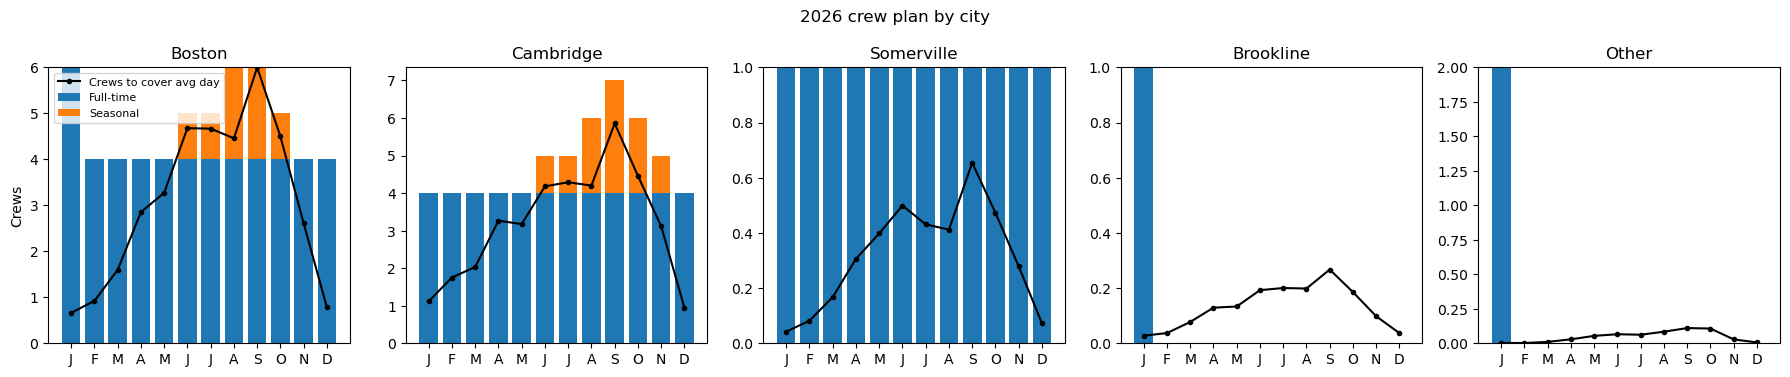

In [27]:
fig, axes = plt.subplots(1, len(CITIES), figsize=(18, 3.8), sharey=False)
for ax, c in zip(axes, CITIES):
    p = plan[plan["city"] == c]; f = forecast[forecast["city"] == c]
    ax.bar(p["month"], p["ft_crews"], label="Full-time")
    ax.bar(p["month"], p["seasonal_crews"], bottom=p["ft_crews"], label="Seasonal")
    need_crews = f.groupby(f["date"].dt.month)["need"].mean() / CREW_DAILY_CAP
    ax.plot(need_crews.index, need_crews.values, "k.-", label="Crews to cover avg day")
    ax.set_title(c); ax.set_xticks(range(1, 13), [m[0] for m in MONTH_NAMES])
axes[0].legend(fontsize=8); axes[0].set_ylabel("Crews")
plt.suptitle("2026 crew plan by city"); plt.tight_layout(); plt.show()

## 7. Backtest on real January to September 2026 trips

The plan was built only from 2024 and 2025 data. Here we measure what actually happened in 2026 with the same simulation and check where the planned crews would have fallen short. We also compare with two references: keeping January crews all year, and a **hindsight** plan optimized with perfect knowledge of 2026.

Backtest, Jan to Sep 2026 (real trips):


,Our plan,Keep Jan crews,Hindsight optimum
Crew cost ($),684900.0,756000.0,775500.0
Lost revenue ($),288922.8,285117.3,163441.8
Total ($),973822.8,1041117.3,938941.8
Need served (%),78.1,78.3,87.6
Short days (city-days),629.0,206.0,572.0


Where our crews fell shortest vs. plan:


,city,Month,total_crews,forecast_need,need,forecast_error_pct,unmet,short_days,lost_revenue
7,Boston,Aug,6,14213.0,21234.0,49.0,5362.0,19,30562.0
5,Boston,Jun,5,14433.0,18662.0,29.0,5294.0,19,30173.0
15,Cambridge,Jul,5,13677.0,17530.0,28.0,5093.0,20,29032.0
6,Boston,Jul,5,14880.0,19234.0,29.0,5384.0,20,30688.0
4,Boston,May,4,10431.0,14104.0,35.0,4254.0,19,24247.0
8,Boston,Sep,6,18505.0,20308.0,10.0,5629.0,18,32085.0
13,Cambridge,May,4,10123.0,12545.0,24.0,3162.0,19,18025.0
16,Cambridge,Aug,6,13393.0,16464.0,23.0,2453.0,16,13983.0


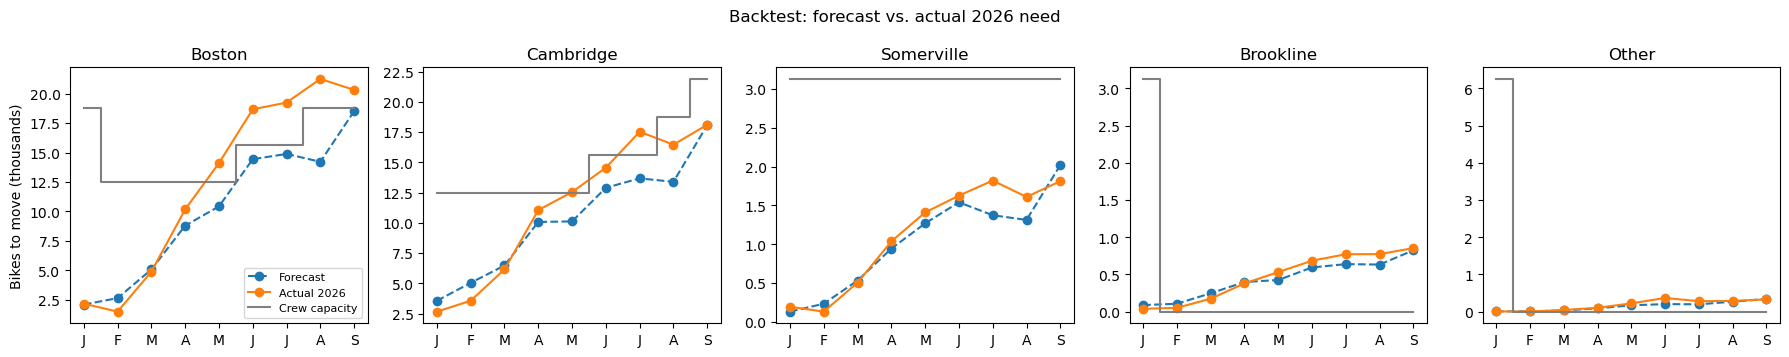

In [28]:
actual = cd[(cd["date"] >= TEST_START) & (cd["date"] <= TEST_END)][["city", "date", "need"]].reset_index(drop=True)
bt_months = range(1, 10)
bt_plan = evaluate(plan, actual, bt_months)
bt_sq = evaluate(status_quo_plan(), actual, bt_months)
hind_input = pd.concat([actual, forecast[forecast["date"] > TEST_END][["city", "date", "need"]]], ignore_index=True)
hind_plan = optimize_plan(hind_input)
bt_hind = evaluate(hind_plan, actual, bt_months)

def tot(e):
    return pd.Series({"Crew cost ($)": e["crew_cost"].sum(), "Lost revenue ($)": e["lost_revenue"].sum(),
                      "Total ($)": e["total_cost"].sum(), "Need served (%)": 100 * (1 - e["unmet"].sum() / e["need"].sum()),
                      "Short days (city-days)": e["short_days"].sum()})
bt_summary = pd.DataFrame({"Our plan": tot(bt_plan), "Keep Jan crews": tot(bt_sq), "Hindsight optimum": tot(bt_hind)})
print("Backtest, Jan to Sep 2026 (real trips):")
display(bt_summary.round(1))

fc_need = evaluate(plan, forecast, bt_months)[["city", "month", "need", "unmet"]].rename(columns={"need": "forecast_need", "unmet": "forecast_unmet"})
gap = bt_plan.merge(fc_need, on=["city", "month"])
gap["forecast_error_pct"] = 100 * (gap["need"] / gap["forecast_need"].replace(0, np.nan) - 1)
gap["extra_unmet_vs_plan"] = gap["unmet"] - gap["forecast_unmet"]
shortfalls = gap.sort_values("extra_unmet_vs_plan", ascending=False).head(8)
shortfalls["Month"] = shortfalls["month"].map(lambda m: MONTH_NAMES[m - 1])
print("Where our crews fell shortest vs. plan:")
display(shortfalls[["city", "Month", "total_crews", "forecast_need", "need", "forecast_error_pct", "unmet", "short_days", "lost_revenue"]].round(0))
gap.to_csv(OUT / "backtest_2026.csv", index=False)

fig, axes = plt.subplots(1, len(CITIES), figsize=(18, 3.6))
for ax, c in zip(axes, CITIES):
    g = gap[gap["city"] == c]
    ax.plot(g["month"], g["forecast_need"] / 1000, "o--", label="Forecast")
    ax.plot(g["month"], g["need"] / 1000, "o-", label="Actual 2026")
    cap = plan[(plan["city"] == c) & (plan["month"] <= 9)]
    ax.step(cap["month"], cap["total_crews"] * CREW_DAILY_CAP * 30.4 / 1000, where="mid", color="gray", label="Crew capacity")
    ax.set_title(c); ax.set_xticks(range(1, 10), [m[0] for m in MONTH_NAMES[:9]])
axes[0].set_ylabel("Bikes to move (thousands)"); axes[0].legend(fontsize=8)
plt.suptitle("Backtest: forecast vs. actual 2026 need"); plt.tight_layout(); plt.show()

## 8. Sensitivity analysis

Scenarios rerun the station simulation on 2024 and 2025 flows, then rebuild the forecast:

* **Ridership ±20%:** all pickups and returns scaled.
* **E-bike growth:** total trips unchanged, but e-bike share raised by 10 or 20 percentage points. Because e-bike trips follow different routes (longer, more uphill and one-way), this changes *where* bikes pile up, not just how many trips happen.

For each scenario we report (a) how the **fixed base plan** performs, and (b) what the **re-optimized** plan would look like.

E-bike share of trips 2024-25: 27.0% | trend: +2.5 pts per year


,Need (k bikes),Base plan: served %,Base plan: total $,Re-opt: served %,Re-opt: total $,Re-opt: peak crews,Re-opt: crew-months,Value of re-planning $
Scenario,,,,,,,,
Base,254.9,89.2,1034574.9,89.2,1034574.9,14,130,0.0
Ridership -20%,132.6,98.2,891804.6,87.1,695454.3,14,77,196350.3
Ridership +20%,430.9,67.3,1680610.5,89.6,1523382.7,22,196,157227.8
E-bike share +10 pts,213.9,94.8,941130.7,90.4,916840.6,14,120,24290.2
E-bike share +20 pts,192.4,95.8,924173.4,88.5,850295.9,14,106,73877.5


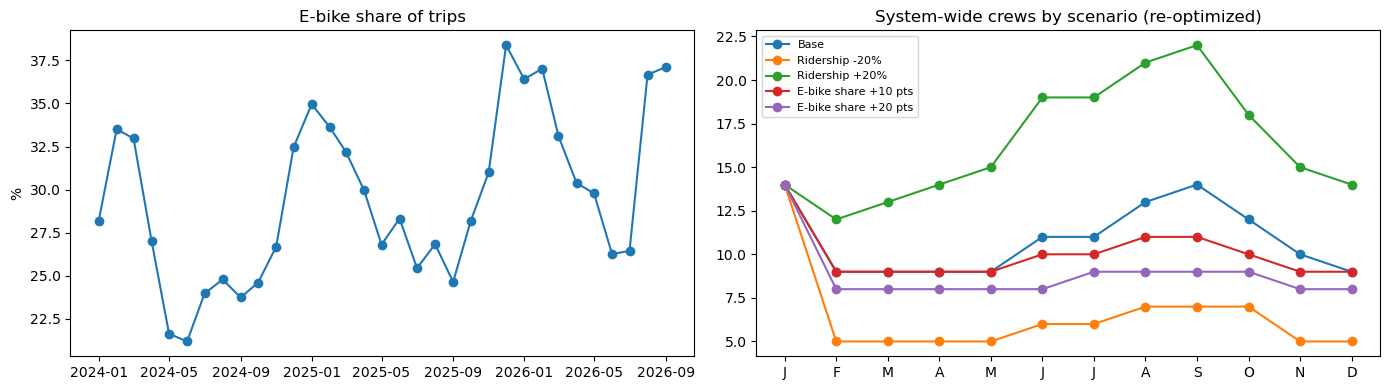

In [29]:
hist_h = hourly[hourly["date"] <= HIST_END]
e_share_hist = float((hist_h["pe"].sum() + hist_h["re"].sum()) / (hist_h[["pc", "pe", "rc", "re"]].to_numpy().sum()))
trend = monthly_summary.assign(t=np.arange(len(monthly_summary)))
slope, intercept = np.polyfit(trend["t"], trend["ebike_share"], 1)
print(f"E-bike share of trips 2024-25: {e_share_hist:.1%} | trend: {slope*1200:+.1f} pts per year")

def scenario_forecast(demand_scale=1.0, ebike_pts=0.0):
    s_new = min(e_share_hist + ebike_pts, 0.95)
    e_mult = s_new / e_share_hist if e_share_hist > 0 else 1.0
    c_mult = (1 - s_new) / (1 - e_share_hist)
    res = simulate(hist_h, demand_scale=demand_scale, e_mult=e_mult, c_mult=c_mult)
    f, _ = forecast_2026(city_daily_from(res, end=HIST_END), uplift_scale=demand_scale)
    return f

SCENARIOS = {"Base": dict(), "Ridership -20%": dict(demand_scale=0.8), "Ridership +20%": dict(demand_scale=1.2),
             "E-bike share +10 pts": dict(ebike_pts=0.10), "E-bike share +20 pts": dict(ebike_pts=0.20)}
sens_rows, sens_plans = [], {}
for name, kw in SCENARIOS.items():
    f = forecast if name == "Base" else scenario_forecast(**kw)
    fixed = evaluate(plan, f)
    p2 = plan if name == "Base" else optimize_plan(f)
    reopt = evaluate(p2, f)
    sens_plans[name] = p2
    sens_rows.append({"Scenario": name, "Need (k bikes)": f["need"].sum() / 1000,
                      "Base plan: served %": 100 * (1 - fixed["unmet"].sum() / fixed["need"].sum()),
                      "Base plan: total $": fixed["total_cost"].sum(),
                      "Re-opt: served %": 100 * (1 - reopt["unmet"].sum() / reopt["need"].sum()),
                      "Re-opt: total $": reopt["total_cost"].sum(),
                      "Re-opt: peak crews": int(p2.groupby("month")["total_crews"].sum().max()),
                      "Re-opt: crew-months": int(p2["total_crews"].sum()),
                      "Value of re-planning $": fixed["total_cost"].sum() - reopt["total_cost"].sum()})
sens = pd.DataFrame(sens_rows).set_index("Scenario")
display(sens.round(1))
sens.to_csv(OUT / "sensitivity.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(pd.to_datetime(monthly_summary["month"], format="%Y%m"), 100 * monthly_summary["ebike_share"], "o-")
ax[0].set_title("E-bike share of trips"); ax[0].set_ylabel("%")
for name, p2 in sens_plans.items():
    ax[1].plot(range(1, 13), p2.groupby("month")["total_crews"].sum(), marker="o", label=name)
ax[1].set_title("System-wide crews by scenario (re-optimized)"); ax[1].set_xticks(range(1, 13), [m[0] for m in MONTH_NAMES])
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

## 9. Operations Assistant: tool-calling agent **[AI-assisted]**

**Technique: agents with tool calling.** The LLM never makes up numbers: it decides which tool to call, our Python model computes the answer, and the LLM explains it. Tools:

| Tool | What it answers |
|---|---|
| `get_crew_plan(city, month)` | Crews, decisions, need, and service level for a city-month |
| `what_if_add_crews(city, month, add_crews)` | Change in unmet need, lost revenue, and crew cost if crews are added or removed |
| `top_imbalance_stations(city, month, n)` | Stations that drain or fill most, from 2025 history |
| `events_in_month(city, month)` | 2026 events and their calibrated uplift |

In [30]:
def _city(c):
    c = str(c).strip().title()
    return c if c in CITIES else "Other"

def _month(m):
    if isinstance(m, str) and not m.strip().isdigit():
        return [n.lower() for n in MONTH_NAMES].index(m.strip()[:3].lower()) + 1
    return int(float(m))

def get_crew_plan(city: str, month: int) -> str:
    """Crew plan for one city and month of 2026 (month 1-12): full-time and seasonal crews, hiring/contract actions, forecast need, unmet need, and real 2026 results when available (Jan-Sep)."""
    c, m = _city(city), _month(month)
    p = plan[(plan["city"] == c) & (plan["month"] == m)].iloc[0]
    e = plan_eval[(plan_eval["city"] == c) & (plan_eval["month"] == m)].iloc[0]
    out = {"city": c, "month": MONTH_NAMES[m - 1], "full_time_crews": int(p["ft_crews"]), "seasonal_crews": int(p["seasonal_crews"]),
           "hires_signed": int(p["hires_signed"]), "release_notices": int(p["release_notices"]),
           "seasonal_contracts_signed": int(p["seasonal_signed"]), "crew_cost_usd": round(float(p["crew_cost"])),
           "forecast_bikes_to_move": round(float(e["need"])), "forecast_unmet": round(float(e["unmet"])),
           "forecast_served_pct": round(float(e["served_pct"]), 1)}
    if m <= 9:
        b = bt_plan[(bt_plan["city"] == c) & (bt_plan["month"] == m)].iloc[0]
        out.update(actual_2026_bikes_to_move=round(float(b["need"])), actual_2026_unmet=round(float(b["unmet"])),
                   actual_2026_served_pct=round(float(b["served_pct"]), 1))
    return json.dumps(out)

def what_if_add_crews(city: str, month: int, add_crews: int = 1) -> str:
    """What happens if we add (or remove, with a negative number) crews in one city and month of 2026. Returns the change in unmet need, lost revenue, and crew cost for a full-time vs seasonal crew, using the forecast and, for Jan-Sep, real 2026 trips."""
    c, m, n = _city(city), _month(month), int(float(add_crews))
    base = int(plan[(plan["city"] == c) & (plan["month"] == m)]["total_crews"].iloc[0])
    new = max(base + n, 0)
    out = {"city": c, "month": MONTH_NAMES[m - 1], "crews_before": base, "crews_after": new}
    for label, df in (("forecast", forecast), ("actual_2026", actual if m <= 9 else None)):
        if df is None: continue
        d = needs_by_city_month(df).get((c, m), np.zeros(1))
        u0 = np.maximum(d - base * CREW_DAILY_CAP, 0).sum(); u1 = np.maximum(d - new * CREW_DAILY_CAP, 0).sum()
        out[label] = {"unmet_before": round(u0), "unmet_after": round(u1), "lost_revenue_saved_usd": round((u0 - u1) * LOST_PER_EVENT)}
    out["added_cost_if_full_time_usd"] = (new - base) * FT_MONTHLY
    out["added_cost_if_seasonal_usd"] = (new - base) * SEASONAL_MONTHLY
    out["notes"] = ("A full-time hire must be signed one month earlier; a seasonal contract must be signed the month before and runs at least 3 months "
                    f"(minimum commitment ${SEASONAL_MONTHLY*3:,}). Seasonal crews are capped at {SEASONAL_CAP} system-wide; this month uses "
                    f"{int(plan[plan['month']==m]['seasonal_crews'].sum())}.")
    return json.dumps(out)

def top_imbalance_stations(city: str, month: int, n: int = 5) -> str:
    """Stations in a city that most often run empty (drain) or full (fill) in a given month, based on 2025 history. Use for hot spots and dispatch questions."""
    c, m = _city(city), _month(month)
    s = station_day[(station_day["city"] == c) & (station_day["date"].dt.year == 2025) & (station_day["date"].dt.month == m)]
    g = s.groupby("sid_code").agg(avg_shortage=("shortage", "mean"), avg_overflow=("overflow", "mean"), avg_net=("net", "mean"))
    g["name"] = station_attrs["name"].to_numpy()[g.index]
    drains = g.sort_values("avg_shortage", ascending=False).head(int(n))
    fills = g.sort_values("avg_overflow", ascending=False).head(int(n))
    fmt = lambda t, col: [{"station": r["name"], f"avg_daily_{col}": round(r[f"avg_{col}"], 1), "avg_daily_net_flow": round(r["avg_net"], 1)} for _, r in t.iterrows()]
    return json.dumps({"city": c, "month": MONTH_NAMES[m - 1], "runs_empty": fmt(drains, "shortage"), "fills_up": fmt(fills, "overflow")})

def events_in_month(city: str, month: int) -> str:
    """2026 events affecting a city in a given month, with expected attendance and the calibrated extra bikes to move."""
    c, m = _city(city), _month(month)
    ed = event_days[(event_days["city"] == c) & (event_days["date"].dt.year == 2026) & (event_days["date"].dt.month == m)]
    ev = events[(events["start_date"].dt.year == 2026)]
    names = {d: ev[(ev["start_date"] <= d) & (ev["end_date"] >= d)]["name"].tolist() for d in ed["date"]}
    return json.dumps([{"date": str(r["date"].date()), "events": names.get(r["date"], []), "category": r["category"],
                        "attendance_in_city": round(r["attendance"]), "extra_bikes_to_move": round(r["uplift"])}
                       for _, r in ed.iterrows()])

TOOL_FUNCS = [get_crew_plan, what_if_add_crews, top_imbalance_stations, events_in_month]

OPS_SYSTEM_PROMPT = """You are the Bluebikes Operations Assistant for dispatchers and planners in Greater Boston.
Answer ONLY from tool results; never invent numbers. Call tools whenever a question involves crews, costs, stations, or events.
Cities: Boston, Cambridge, Somerville, Brookline, Other. Months are 2026, given as numbers 1-12.
Keep answers short and practical: lead with the recommendation, then 2-4 supporting numbers, then any rule that applies
(hiring lead time, 3-month seasonal minimum, 8 seasonal crew cap). Money in USD."""

def ask_ops(question, max_steps=6, verbose=True):
    from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
    from langchain_core.tools import tool
    tools = [tool(f) for f in TOOL_FUNCS]
    tmap = {t.name: t for t in tools}
    agent = llm.bind_tools(tools)
    msgs = [SystemMessage(OPS_SYSTEM_PROMPT), HumanMessage(question)]
    for _ in range(max_steps):
        ai = agent.invoke(msgs); msgs.append(ai)
        if not ai.tool_calls:
            text = ai.content if isinstance(ai.content, str) else "".join(p.get("text", "") for p in ai.content if isinstance(p, dict))
            return text
        for tc in ai.tool_calls:
            if verbose: print(f"  → {tc['name']}({tc['args']})")
            out = tmap[tc["name"]].invoke(tc["args"])
            msgs.append(ToolMessage(content=str(out), tool_call_id=tc["id"]))
    return "Stopped after max steps."

DEMO_QUESTIONS = [
    "What happens if we add one crew to Cambridge in September?",
    "Which Cambridge stations run empty most in October, and what events are coming that month?",
    "How many crews does Boston have in July 2026, and when do we need to sign the seasonal contracts?",
]

if llm is not None:
    for q in DEMO_QUESTIONS:
        print(f"\nQ: {q}")
        try:
            print("A:", ask_ops(q))
        except Exception as ex:
            print("Assistant error:", ex)
else:
    print("No API key: showing the tools the agent would call.\n")
    print("what_if_add_crews('Cambridge', 9, 1) →", what_if_add_crews("Cambridge", 9, 1))
    print("\nget_crew_plan('Boston', 7) →", get_crew_plan("Boston", 7))


Q: What happens if we add one crew to Cambridge in September?
  → what_if_add_crews({'add_crews': 1, 'city': 'Cambridge', 'month': 9})
A: Add one crew to Cambridge in September.

* **Actual (Jan–Sep) results:** Saved **$7,999** in lost revenue while reducing unmet need from 2,360 to 957 trips (crews increased from 7 to 8).
* **Forecasted impact:** Expected to save **$7,113** in lost revenue and reduce unmet need from 1,465 to 217 trips.
* **Added costs:** **$6,000** for a full-time crew vs. **$7,800** for a seasonal crew.

**Rules to keep in mind:**
* Full-time hires require a **1-month hiring lead time** (must sign in August).
* Seasonal contracts must be signed the month before, run a **3-month minimum** (minimum commitment **$23,400**), and seasonal crews are **capped at 8 system-wide** (this month uses 5).

Q: Which Cambridge stations run empty most in October, and what events are coming that month?
  → top_imbalance_stations({'n': 5, 'city': 'Cambridge', 'month': 10})
  → events_

In [34]:
print(ask_ops("Should Somerville get a seasonal crew this summer?"))

  → get_crew_plan({'month': '6', 'city': 'Somerville'})
  → get_crew_plan({'city': 'Somerville', 'month': '7'})
  → get_crew_plan({'month': '8', 'city': 'Somerville'})
  → what_if_add_crews({'month': '6', 'add_crews': 1, 'city': 'Somerville'})
  → what_if_add_crews({'add_crews': 1, 'month': '7', 'city': 'Somerville'})
  → what_if_add_crews({'add_crews': 1, 'month': '8', 'city': 'Somerville'})
Somerville does not need an additional seasonal crew for the summer. The existing 1 full-time crew covers nearly all demand (99.3% to 100% served), and adding a crew only recovers $75 in lost revenue in July at a cost of $7,800.

* **July actuals:** 13 unmet needs and 99.3% served, with $75 in potential lost revenue saved by adding a crew.
* **June & August actuals:** 0 unmet needs and 100% served.
* **Cost:** A seasonal crew costs $7,800/month and requires a mandatory 3-month minimum commitment ($23,400 total), far exceeding any operational savings.


## 10. Other considerations: chronic sinks and sources

Some stations gain or lose bikes almost every day. Crews fix these daily, but structural fixes may be cheaper:
**extra docks or valet docking** at chronic sinks (stations that fill up), and **rider rewards** for returning bikes to chronic sources (stations that drain), similar to Lyft's Bike Angels program.

In [32]:
summer25 = station_day[(station_day["date"] >= "2025-06-01") & (station_day["date"] <= "2025-09-30")]
chronic = summer25.groupby("sid_code").agg(avg_net=("net", "mean"), avg_need=("need", "mean"),
                                           pct_days_overflow=("overflow", lambda s: 100 * (s > 0).mean()),
                                           pct_days_short=("shortage", lambda s: 100 * (s > 0).mean()))
chronic["station"] = station_attrs["name"].to_numpy()[chronic.index]
chronic["city"] = CITY_OF[chronic.index]
chronic["docks"] = CAP[chronic.index]
print("Chronic sinks, summer 2025 (gain bikes): candidates for more docks or valet docking")
display(chronic.sort_values("avg_net", ascending=False).head(8)[["station", "city", "docks", "avg_net", "pct_days_overflow"]].round(1))
print("Chronic sources (lose bikes): candidates for return rewards")
display(chronic.sort_values("avg_net").head(8)[["station", "city", "docks", "avg_net", "pct_days_short"]].round(1))

Chronic sinks, summer 2025 (gain bikes): candidates for more docks or valet docking


,station,city,docks,avg_net,pct_days_overflow
sid_code,,,,,
455,Ames St at Main St,Cambridge,19.0,31.9,95.9
5,Longwood Ave at Binney St,Boston,15.0,10.4,93.4
12,Packard's Corner - Commonwealth Ave at Brighto...,Boston,27.0,6.5,21.3
267,Boylston St at Arlington St,Boston,31.0,5.4,66.4
25,Nashua Street at Red Auerbach Way,Boston,37.0,5.1,17.2
188,Farragut Rd at E. 6th St,Boston,23.0,5.1,13.9
41,Western Ave at Leo Birmingham Pkwy,Boston,16.0,5.0,0.0
171,Watermark Seaport - Boston Wharf Rd at Seaport...,Boston,15.0,5.0,90.2


Chronic sources (lose bikes): candidates for return rewards


,station,city,docks,avg_net,pct_days_short
sid_code,,,,,
460,MIT Vassar St,Cambridge,53.0,-12.1,95.1
99,Government Center - Cambridge St at Court St,Boston,40.0,-11.7,24.6
314,The Overlook at St. Gabriel's,Boston,19.0,-7.9,59.0
479,Mass Ave at Albany St,Cambridge,18.0,-6.5,65.6
489,MIT Hayward St at Amherst St,Cambridge,27.0,-6.4,46.7
426,MIT at Mass Ave / Amherst St,Cambridge,31.0,-6.3,41.0
568,Craigie St at Summer St,Somerville,19.0,-6.1,53.3
444,359 Broadway - Broadway at Fayette Street,Cambridge,23.0,-6.0,89.3


## 11. Analysis & justification (auto-generated from the results above)

In [33]:
pe, se = plan_eval, sq_eval
peak_m = int(plan.groupby("month")["total_crews"].sum().idxmax())
low_m = int(plan.groupby("month")["total_crews"].sum().idxmin())
n_hires = int(plan["hires_signed"].sum()); n_rel = int(plan["release_notices"].sum())
n_seas = int(plan["seasonal_signed"].sum()); seas_peak = int(plan.groupby("month")["seasonal_crews"].sum().max())
worst = shortfalls.iloc[0]
r20 = sens.loc["Ridership +20%"]; m20 = sens.loc["Ridership -20%"]; eb = sens.loc["E-bike share +20 pts"]

report = f"""
**Key decisions.** System-wide crews peak in **{MONTH_NAMES[peak_m-1]}** at {int(plan.groupby('month')['total_crews'].sum().max())} and bottom out in **{MONTH_NAMES[low_m-1]}** at {int(plan.groupby('month')['total_crews'].sum().min())}.
The plan signs **{n_seas} seasonal contracts** (peak {seas_peak} of the 8 allowed), makes **{n_hires} full-time hires**, and issues **{n_rel} release notices**.
Full-time crews carry the year-round base load because they cost $6,000/month versus $7,800 for seasonal, while seasonal contracts absorb the summer peak because hiring
and later releasing a full-time driver costs $4,500 (training) + $13,500 (release) on top of salary. A crew is worth adding whenever it prevents more than
~{FT_MONTHLY/LOST_PER_EVENT:,.0f} lost rider events a month, and the MILP applies that test month by month using real daily peaks rather than monthly averages.

**Cost and revenue impact (2026 forecast).** Optimized plan: crew cost ${pe['crew_cost'].sum():,.0f}, lost revenue ${pe['lost_revenue'].sum():,.0f},
total ${pe['total_cost'].sum():,.0f}, serving {100*(1-pe['unmet'].sum()/pe['need'].sum()):.1f}% of rebalancing need. Keeping January crews all year:
total ${se['total_cost'].sum():,.0f}, serving {100*(1-se['unmet'].sum()/se['need'].sum()):.1f}%. **Net benefit: ${se['total_cost'].sum()-pe['total_cost'].sum():,.0f}.**

**Backtest (real Jan to Sep 2026).** Our plan served {bt_summary.loc['Need served (%)','Our plan']:.1f}% of need at a total cost of ${bt_summary.loc['Total ($)','Our plan']:,.0f},
versus ${bt_summary.loc['Total ($)','Keep Jan crews']:,.0f} for the status quo and ${bt_summary.loc['Total ($)','Hindsight optimum']:,.0f} for a perfect-hindsight plan.
The largest shortfall was **{worst['city']} in {worst['Month']}**, where actual need was {worst['forecast_error_pct']:+.0f}% versus forecast and crews fell short on {int(worst['short_days'])} days.

**Sensitivity.** With ridership +20%, the base plan serves {r20['Base plan: served %']:.1f}% and re-planning saves ${r20['Value of re-planning $']:,.0f};
with ridership −20%, re-planning saves ${m20['Value of re-planning $']:,.0f} by avoiding idle crews. E-bike share +20 pts changes need to {eb['Need (k bikes)']:,.0f}k bikes
(base {sens.loc['Base','Need (k bikes)']:,.0f}k). Because seasonal contracts can be signed monthly and end at no cost, the plan adapts to demand surprises
within one month; the binding risk is the 8-crew seasonal cap in peak months.

**Key assumptions.** Stations reset to half full each night; same-hour pickups and returns net out (understates need); each unmet unit is one affected rider at $5.70;
crews work 6 of 7 days, staggered, so capacity is 102.9 bikes/crew/day; trainees are paid but do not work; January 2026 crews are full-time;
event uplift is calibrated from 2024 to 2025 data (Red Sox attendance assumed at 32,000).
"""
display(Markdown(report))
with open(OUT / "analysis_report.md", "w") as fh:
    fh.write(report)
print("Saved outputs:", sorted(p.name for p in OUT.iterdir()))


**Key decisions.** System-wide crews peak in **Jan** at 14 and bottom out in **Feb** at 9.
The plan signs **5 seasonal contracts** (peak 5 of the 8 allowed), makes **0 full-time hires**, and issues **5 release notices**.
Full-time crews carry the year-round base load because they cost $6,000/month versus $7,800 for seasonal, while seasonal contracts absorb the summer peak because hiring
and later releasing a full-time driver costs $4,500 (training) + $13,500 (release) on top of salary. A crew is worth adding whenever it prevents more than
~1,053 lost rider events a month, and the MILP applies that test month by month using real daily peaks rather than monthly averages.

**Cost and revenue impact (2026 forecast).** Optimized plan: crew cost $878,100, lost revenue $156,475,
total $1,034,575, serving 89.2% of rebalancing need. Keeping January crews all year:
total $1,190,591, serving 87.4%. **Net benefit: $156,016.**

**Backtest (real Jan to Sep 2026).** Our plan served 78.1% of need at a total cost of $973,823,
versus $1,041,117 for the status quo and $938,942 for a perfect-hindsight plan.
The largest shortfall was **Boston in Aug**, where actual need was +49% versus forecast and crews fell short on 19 days.

**Sensitivity.** With ridership +20%, the base plan serves 67.3% and re-planning saves $157,228;
with ridership −20%, re-planning saves $196,350 by avoiding idle crews. E-bike share +20 pts changes need to 192k bikes
(base 255k). Because seasonal contracts can be signed monthly and end at no cost, the plan adapts to demand surprises
within one month; the binding risk is the 8-crew seasonal cap in peak months.

**Key assumptions.** Stations reset to half full each night; same-hour pickups and returns net out (understates need); each unmet unit is one affected rider at $5.70;
crews work 6 of 7 days, staggered, so capacity is 102.9 bikes/crew/day; trainees are paid but do not work; January 2026 crews are full-time;
event uplift is calibrated from 2024 to 2025 data (Red Sox attendance assumed at 32,000).


Saved outputs: ['analysis_report.md', 'backtest_2026.csv', 'crew_plan_2026.csv', 'sensitivity.csv']
